# ИДЗ №1. Эмпирический и теоретический анализ алгоритмов сортировки

**Студент:** *Макеров Фёдор Михайлович*  
**Группа:** *Б06-505*  
**Вариант:** Stupid Sort, Insertion Sort, QuickSort (разбиение Хоара).

> Этот ноутбук составлен как обучающий отчёт. Перед сдачей выполни **полный эксперимент**, заполни свои данные и напиши выводы по **реальным** замерам. Не оставляй учебные результаты в качестве финального исследования.

**Цели:** проверить корректность сортировок, сравнить время на пяти распределениях, показать графики с погрешностями, оценить закон роста по Log-Log и сопоставить измерения с теорией.

## 1. Что мы исследуем

**Массив** — список значений: `[3, 1, 2]`. Сортировка превращает его в `[1, 2, 3]`.

- **Stupid Sort:** если два соседних элемента стоят неправильно, меняем местами и возвращаемся в начало. Худшее время $O(N^3)$, лучший случай $O(N)$.
- **Insertion Sort:** вставляем каждый следующий элемент в отсортированную левую часть. Худшее время $O(N^2)$, лучший случай $O(N)$.
- **QuickSort (Hoare):** выбираем опорное значение, разделяем массив на части и сортируем их рекурсивно. Среднее время $O(N\log N)$, худшее $O(N^2)$.

**Особенность варианта:** на сайте курса ФБМФ МФТИ Stupid Sort описана как возврат в начало после обмена и имеет **кубическую** сложность. В PDF ТЗ она указана среди квадратичных алгоритмов. Мы следуем описанию алгоритма из курса и будем явно проверять $N^3$. [Источник](https://cs.mipt.ru/fbmf/lessons/sem_1/08.sorts.html).

Все три функции написаны вручную в `sorts.py`, без `sort()` и `sorted()` внутри алгоритмов.

## 2. Настройки и подключение модулей

**Ячейка с кодом** выполняется через `Shift+Enter`. `import` подключает функции из других Python-файлов в папке проекта. `FULL_RUN=False` — учебная короткая серия; для финального отчёта поставь **True** и перезапусти все ячейки.

In [13]:
FULL_RUN = False  # Перед итоговой сдачей обязательно переключить на True.
REPEATS = 5  # Минимум из ТЗ: пять независимых повторов на точку.
CHOSEN_DISTRIBUTION = "random"  # Тип для крупных детальных графиков ниже.

from sorts import SORTS, OPERATION_LABELS
from experiments import (DISTRIBUTIONS, DEMO_SIZES, FULL_SIZES,
                         generate_data, benchmark, memory_profile, save_csv)
from charts import (plot_time, plot_loglog, plot_fitting, plot_memory,
                    subset, slope_loglog)
import pandas as pd
import matplotlib.pyplot as plt

SIZES = FULL_SIZES if FULL_RUN else DEMO_SIZES
print("Режим:", "ПОЛНЫЙ" if FULL_RUN else "ДЕМОНСТРАЦИОННЫЙ")
print("Количество повторов на точку:", REPEATS)
print("Сетки размеров N:", SIZES)

Режим: ДЕМОНСТРАЦИОННЫЙ
Количество повторов на точку: 5
Сетки размеров N: {'Stupid Sort': [20, 40, 60, 80, 100], 'Insertion Sort': [100, 200, 400, 800, 1200], 'Quick Sort (Hoare)': [100, 500, 1000, 3000, 6000]}


## 3. Как работает каждая сортировка на маленьком примере

Пусть входной массив `[3, 1, 2]`.

**Stupid:** `[3,1,2] → [1,3,2] → [1,2,3]`. После *каждого* обмена снова смотрим с первого элемента.

**Insertion:** берём `1`, сдвигаем `3`, вставляем `1`; потом берём `2`, сдвигаем `3`, вставляем `2`.

**QuickSort:** два указателя `i` и `j` идут навстречу друг другу, проверяя элементы относительно значения `pivot`. После разбиения обе части сортируются тем же методом.

Возвращаемое значение функции: `(отсортированный_массив, comparisons, swaps_or_writes)`. Третий счётчик в сортировке вставками — **записи**, в двух остальных — **обмены**.

In [14]:
example = [3, 1, 2]
for name, sorting_function in SORTS.items():
    result, comparisons, operations = sorting_function(example.copy())
    print(f"{name}: {result}; сравнений={comparisons}; "
          f"{OPERATION_LABELS[name]}={operations}")
print("Исходный массив остался прежним:", example)

Stupid Sort: [1, 2, 3]; сравнений=5; обмены=2
Insertion Sort: [1, 2, 3]; сравнений=3; записи=4
Quick Sort (Hoare): [1, 2, 3]; сравнений=9; обмены=2
Исходный массив остался прежним: [3, 1, 2]


## 4. Автоматическая проверка

Мы не можем доверять графикам, если алгоритм сортирует неверно. Проверим пустой массив, один элемент, одинаковые числа, обратный порядок, отрицательные числа, дубликаты и все 5 типов входных данных. Здесь `sorted()` используется **только как эталон в проверках**, не в коде сортировок.

In [15]:
examples = [[], [5], [2, 2, 2], [3, 1, 2], [8, -3, 0, -3], [4, 3, 2, 1]]
checks = 0
for name, sorting_function in SORTS.items():
    for source in examples:
        result, _, _ = sorting_function(source.copy())
        assert result == sorted(source), f"Ошибка {name} на {source}"
        checks += 1
    for kind in DISTRIBUTIONS:
        source = generate_data(40, kind, seed=123)
        result, _, _ = sorting_function(source.copy())
        assert result == sorted(source)
        checks += 1
print("Успешных проверок:", checks)

Успешных проверок: 33


## 5. Какие массивы мы создаём

Нужно **пять** распределений из ТЗ: случайный, отсортированный, обратно отсортированный, почти отсортированный (меняем примерно 5% позиций) и с большим числом повторов (значения только из множества 1…5).

**Seed** — число, от которого зависит псевдослучайный генератор. Одинаковый seed позволяет получить тот же массив повторно.

In [16]:
for kind, russian_name in DISTRIBUTIONS.items():
    sample = generate_data(20, kind, seed=42)
    print(f"{russian_name:26s}: {sample}")

Случайный                 : [20, -13, -19, -3, -5, -6, -12, -14, 14, -15, 17, 7, -18, -19, -15, -7, -6, 12, 18, -19]
Отсортированный           : [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]
Обратно отсортированный   : [20, 19, 18, 17, 16, 15, 14, 13, 12, 11, 10, 9, 8, 7, 6, 5, 4, 3, 2, 1]
Почти отсортированный     : [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]
Много повторений          : [1, 1, 3, 2, 2, 2, 1, 5, 1, 5, 4, 1, 1, 1, 2, 2, 5, 5, 1, 5]


## 6. Измеряем время честно

**Что входит в таймер:** только вызов функции сортировки.  
**Что не входит:** генерация массива, его копирование, проверка результата, построение графика.

Для каждой комбинации `(алгоритм, тип, N)` делаем **REPEATS** измерений с разными seed, считаем среднее и выборочное стандартное отклонение. Для Stupid Sort не превышаем N=500. В деморежиме сетки уменьшены, чтобы освоить интерфейс; для финального отчёта выбираем `FULL_RUN=True`.

⚠️ Полный эксперимент, особенно Stupid Sort при N=500 и 5 распределениях, может занимать значительное время. Это ожидаемо, не останавливай ядро без необходимости.

In [17]:
raw_rows, summary_rows = benchmark(
    names=list(SORTS),
    distributions=list(DISTRIBUTIONS),
    sizes=SIZES,
    repeats=REPEATS,
    progress=print,
)
print("Сырых записей:", len(raw_rows))
print("Агрегированных точек:", len(summary_rows))

Stupid Sort, Случайный, N=20: готово
Stupid Sort, Отсортированный, N=20: готово
Stupid Sort, Обратно отсортированный, N=20: готово
Stupid Sort, Почти отсортированный, N=20: готово
Stupid Sort, Много повторений, N=20: готово
Stupid Sort, Случайный, N=40: готово
Stupid Sort, Отсортированный, N=40: готово
Stupid Sort, Обратно отсортированный, N=40: готово
Stupid Sort, Почти отсортированный, N=40: готово
Stupid Sort, Много повторений, N=40: готово
Stupid Sort, Случайный, N=60: готово
Stupid Sort, Отсортированный, N=60: готово
Stupid Sort, Обратно отсортированный, N=60: готово
Stupid Sort, Почти отсортированный, N=60: готово
Stupid Sort, Много повторений, N=60: готово
Stupid Sort, Случайный, N=80: готово
Stupid Sort, Отсортированный, N=80: готово
Stupid Sort, Обратно отсортированный, N=80: готово
Stupid Sort, Почти отсортированный, N=80: готово
Stupid Sort, Много повторений, N=80: готово
Stupid Sort, Случайный, N=100: готово
Stupid Sort, Отсортированный, N=100: готово
Stupid Sort, Обратно о

## 7. Таблицы сырых измерений и средних значений

`DataFrame` — таблица из библиотеки `pandas`. У каждой сырой записи есть время `time_ms`, алгоритм, тип массива, размер, повтор и seed. В итоговой таблице `mean_ms` — среднее время, `std_ms` — стандартное отклонение, `mean_comparisons` — среднее количество сравнений.

В итоговом отчёте должны присутствовать **реальные** результаты полного эксперимента, а не придуманные значения.

In [18]:
raw_df = pd.DataFrame(raw_rows)
summary_df = pd.DataFrame(summary_rows)
display(raw_df.head(15))
display(summary_df)
print("Тип операции:", OPERATION_LABELS)

,algorithm,distribution,n,repeat,seed,time_ms,comparisons,operations,operation_type
0,Stupid Sort,random,20,1,2366,0.2318,821,83,обмены
1,Stupid Sort,random,20,2,3375,0.2093,751,86,обмены
2,Stupid Sort,random,20,3,4384,0.2650,965,99,обмены
3,Stupid Sort,random,20,4,5393,0.2666,952,105,обмены
4,Stupid Sort,random,20,5,6402,0.2608,939,103,обмены
5,Stupid Sort,sorted,20,1,2366,0.0071,19,0,обмены
6,Stupid Sort,sorted,20,2,3375,0.0055,19,0,обмены
7,Stupid Sort,sorted,20,3,4384,0.0054,19,0,обмены
8,Stupid Sort,sorted,20,4,5393,0.0055,19,0,обмены
9,Stupid Sort,sorted,20,5,6402,0.0054,19,0,обмены


,algorithm,distribution,n,mean_ms,std_ms,mean_comparisons,mean_operations,operation_type,repeats
0,Stupid Sort,random,20,0.24670,0.025251,885.6,95.2,обмены,5
1,Stupid Sort,sorted,20,0.00578,0.000740,19.0,0.0,обмены,5
2,Stupid Sort,reversed,20,0.39386,0.029800,1349.0,190.0,обмены,5
3,Stupid Sort,nearly_sorted,20,0.02226,0.017440,73.8,7.0,обмены,5
4,Stupid Sort,duplicates,20,0.24138,0.070590,763.0,78.2,обмены,5
...,...,...,...,...,...,...,...,...,...
70,Quick Sort (Hoare),random,6000,23.66802,7.126608,108946.6,18003.6,обмены,5
71,Quick Sort (Hoare),sorted,6000,11.88740,4.843722,81807.0,0.0,обмены,5
72,Quick Sort (Hoare),reversed,6000,13.06004,3.587899,81808.0,3000.0,обмены,5
73,Quick Sort (Hoare),nearly_sorted,6000,17.78076,0.296086,82251.4,606.4,обмены,5


Тип операции: {'Stupid Sort': 'обмены', 'Insertion Sort': 'записи', 'Quick Sort (Hoare)': 'обмены'}


## 8. График 1: время от размера массива, линейные оси

- Горизонтальная ось X — `N`, количество элементов.
- Вертикальная ось Y — `T(N)`, среднее время в **миллисекундах**.
- Линии показывают алгоритмы. Сетка помогает сравнивать значения, легенда объясняет цвета.
- Вертикальные «усы» — **±1 стандартное отклонение**, не 95%-й доверительный интервал.

У разных алгоритмов в ТЗ разные сетки N. Поэтому они визуально занимают разные части общей оси. Это не ошибка.

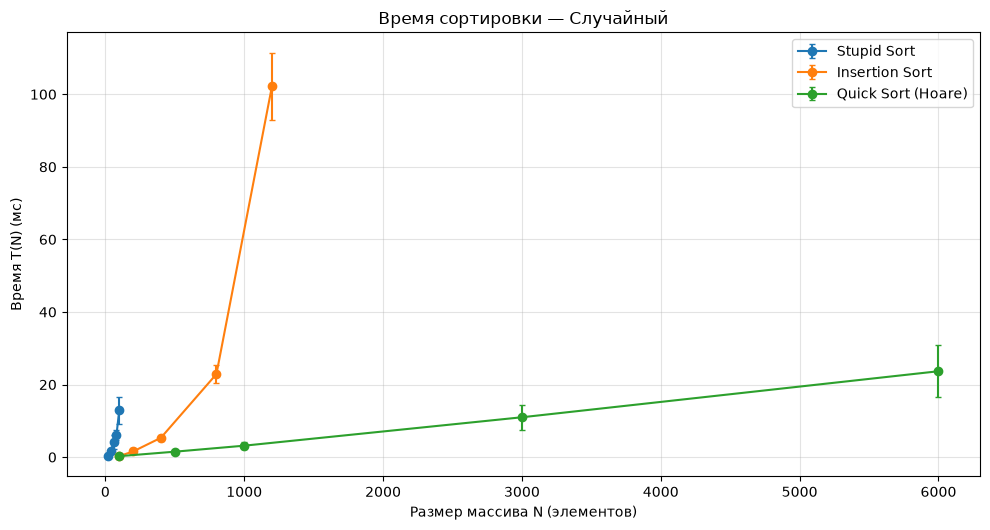

In [19]:
fig = plot_time(summary_rows, CHOSEN_DISTRIBUTION)
plt.show()

## 9. График 2: двойной логарифмический масштаб (Log-Log)

Если время подчиняется степенной зависимости $T(N) = cN^k$, то $\log T(N) = k\log N + \log c$. На Log-Log графике получается почти прямая, её наклон равен показателю $k$.

Ожидания на типичных больших наборах: Stupid Sort (случайный/обратный) — около 3; Insertion Sort (случайный/обратный) — около 2; QuickSort — около 1–1.15. Для отсортированного списка Stupid и Insertion растут примерно как $N^1$. Реальные наклоны могут отличаться: они зависят от набора размеров, шума замеров и поведения Python.

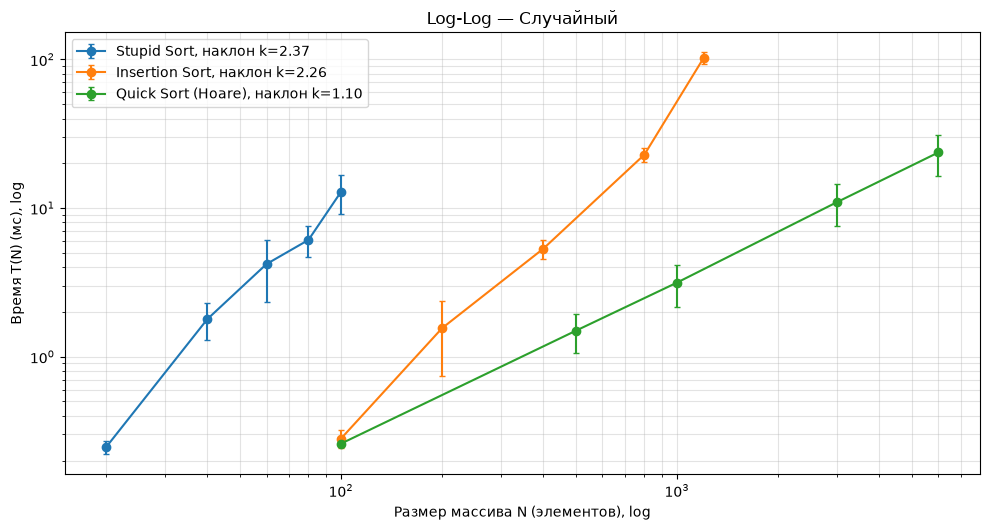

Наклоны Log-Log по реальным измерениям:
Stupid Sort: 2.371
Insertion Sort: 2.259
Quick Sort (Hoare): 1.103


In [20]:
fig, slopes = plot_loglog(summary_rows, CHOSEN_DISTRIBUTION)
plt.show()
print("Наклоны Log-Log по реальным измерениям:")
for name, slope in slopes.items():
    print(f"{name}: {slope:.3f}" if slope is not None else name + ": мало точек")

## 10. График 3: теоретическая аппроксимация (fitting)

Экспериментальные времена изображаются точками, теоретическая зависимость — плавной линией. Принцип: $T(N) \approx c f(N)$, где $f(N)$ — $N$, $N^2$, $N^3$ или $N\log_2N$. Коэффициент $c$ подбираем **методом наименьших квадратов** (МНК):

$$c = \frac{\sum_i f(N_i)\,T_i}{\sum_i f(N_i)^2}.$$

Функция `fit_coefficient` вычисляет эту формулу. Это **подгонка коэффициента**, а не доказательство математической сложности. Теория задаёт ожидаемую форму зависимости.

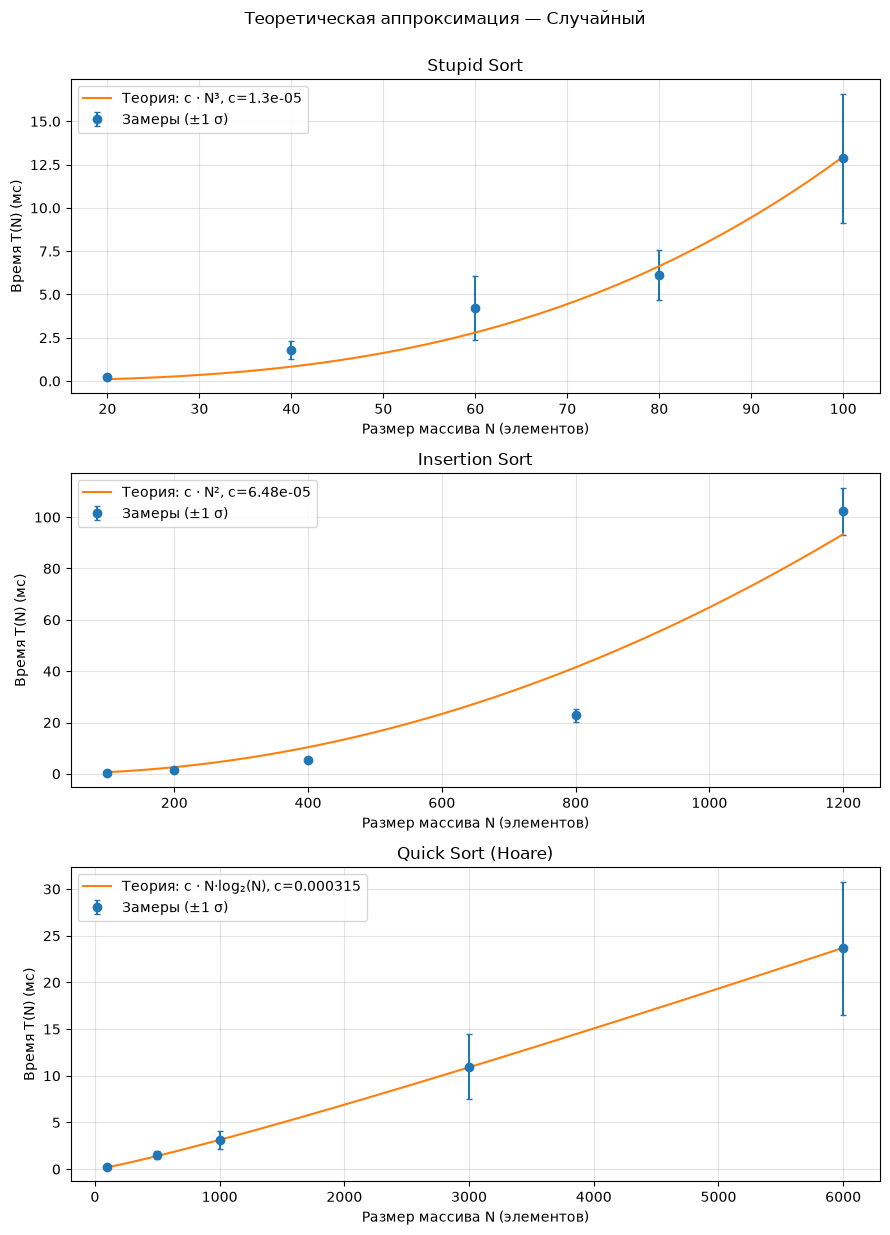

Stupid Sort: T(N) ≈ 1.2959e-05 × c · N³
Insertion Sort: T(N) ≈ 6.484e-05 × c · N²
Quick Sort (Hoare): T(N) ≈ 0.00031484 × c · N·log₂(N)


In [21]:
fig, coefficients = plot_fitting(summary_rows, CHOSEN_DISTRIBUTION)
plt.show()
for name, (model, coefficient) in coefficients.items():
    print(f"{name}: T(N) ≈ {coefficient:.5g} × {model}")

## 11. Сравнение всех пяти распределений

Для каждого типа входных данных ниже строится компактная пара графиков: линейный и Log-Log, чтобы проверить изменение поведения. Это также помогает заметить, что почти отсортированные входы для Insertion Sort обычно выгоднее случайных, а обратный порядок хуже.


 СЛУЧАЙНЫЙ


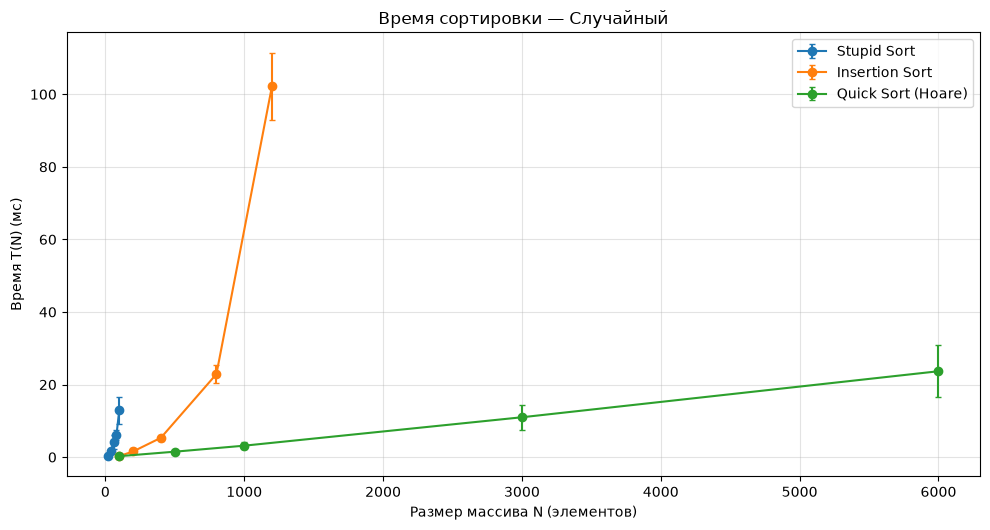

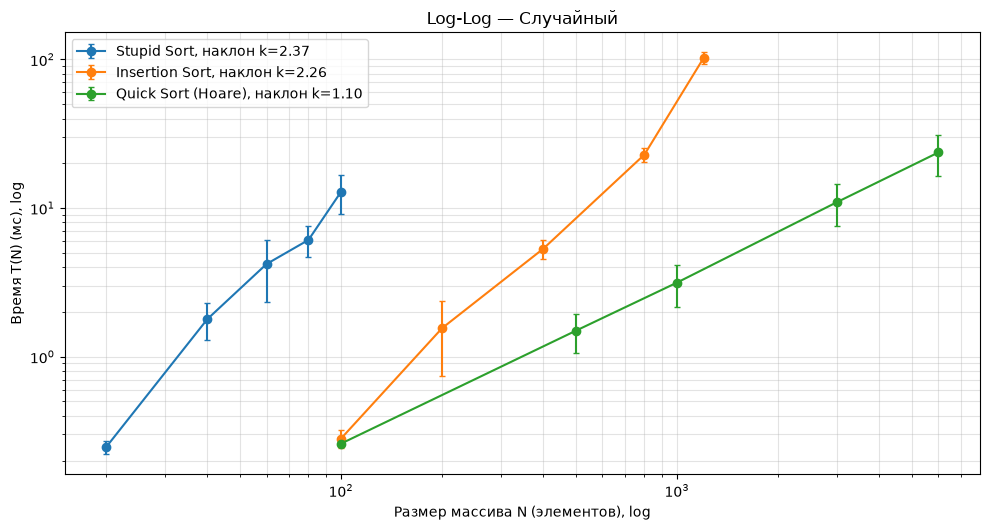

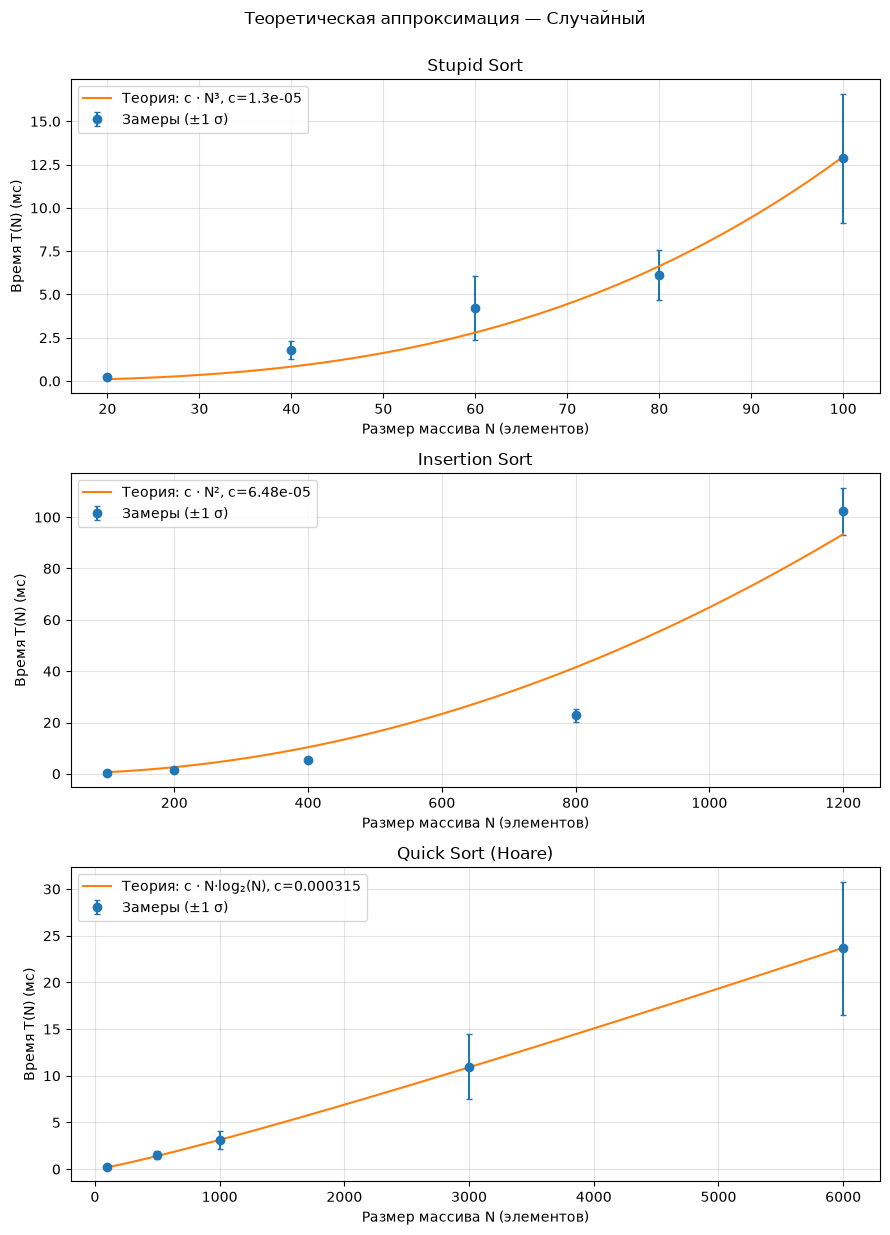

Оценки наклона: {'Stupid Sort': 2.371, 'Insertion Sort': 2.259, 'Quick Sort (Hoare)': 1.103}

 ОТСОРТИРОВАННЫЙ


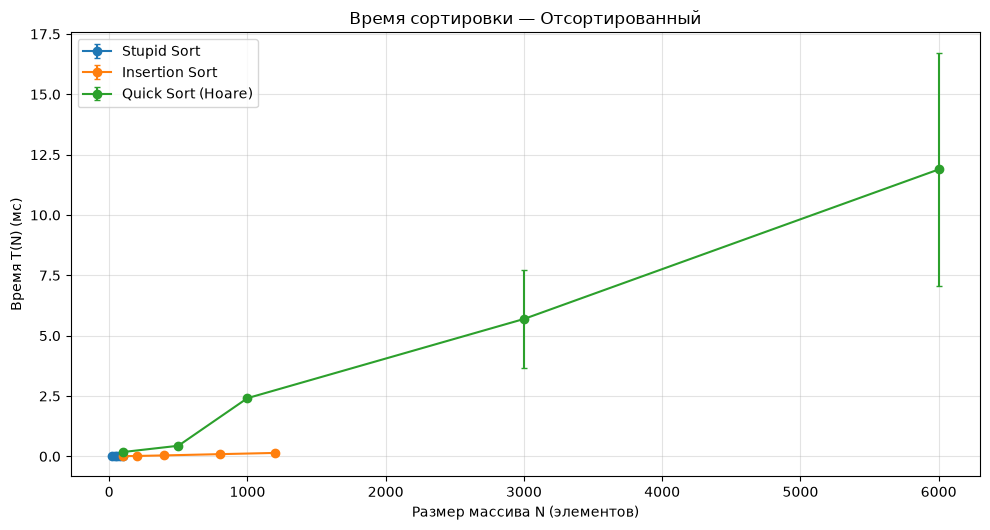

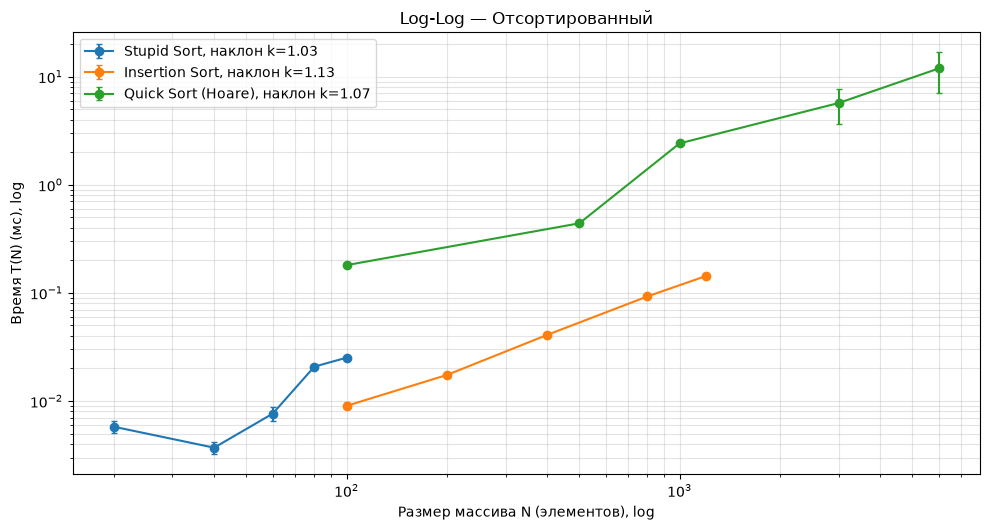

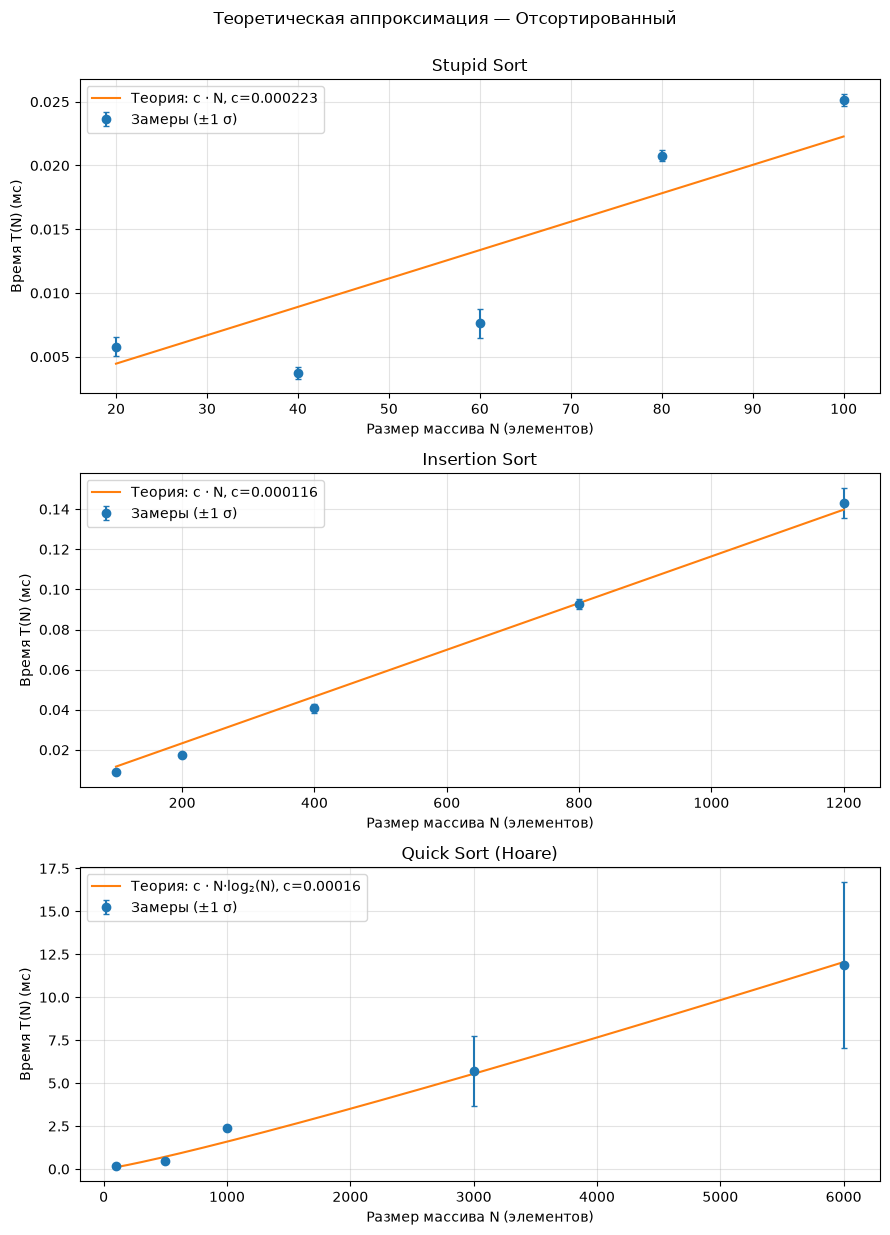

Оценки наклона: {'Stupid Sort': 1.031, 'Insertion Sort': 1.133, 'Quick Sort (Hoare)': 1.07}

 ОБРАТНО ОТСОРТИРОВАННЫЙ


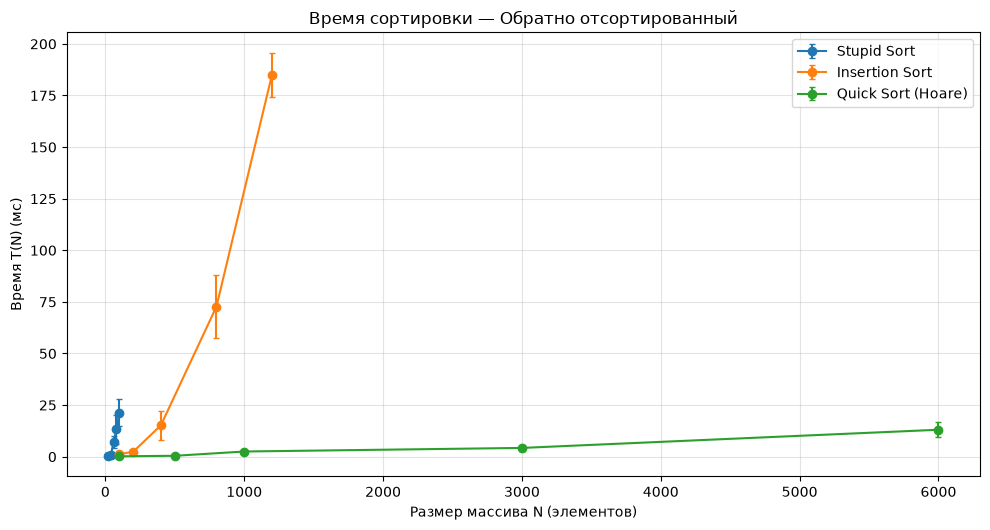

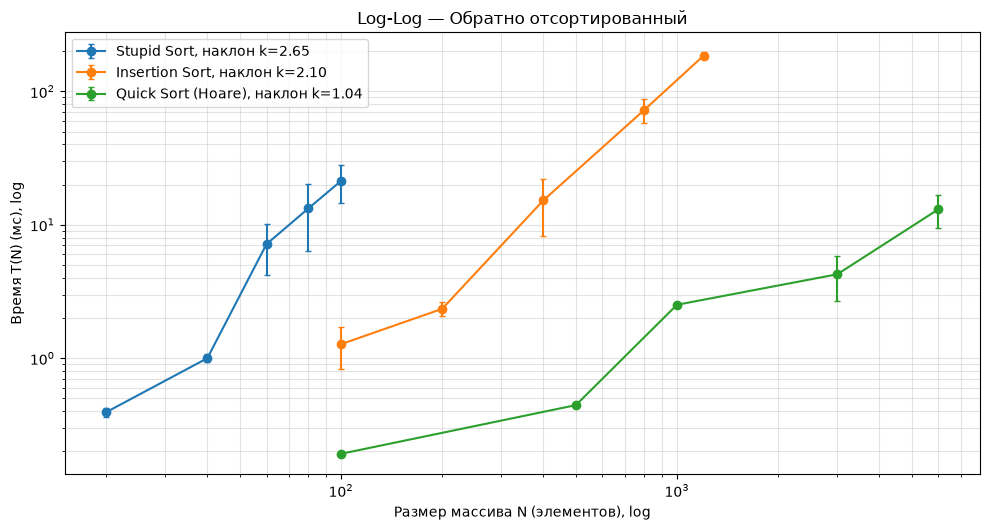

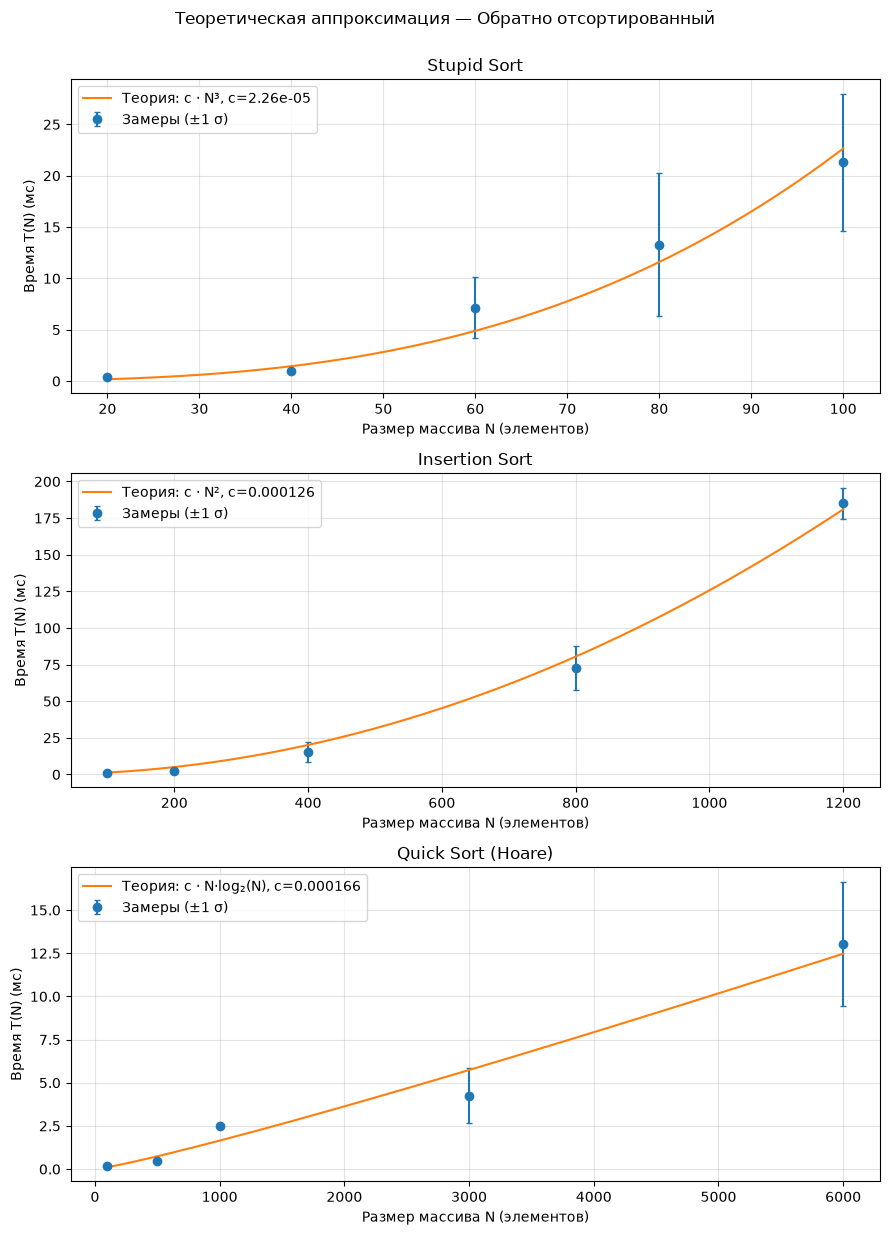

Оценки наклона: {'Stupid Sort': 2.645, 'Insertion Sort': 2.098, 'Quick Sort (Hoare)': 1.04}

 ПОЧТИ ОТСОРТИРОВАННЫЙ


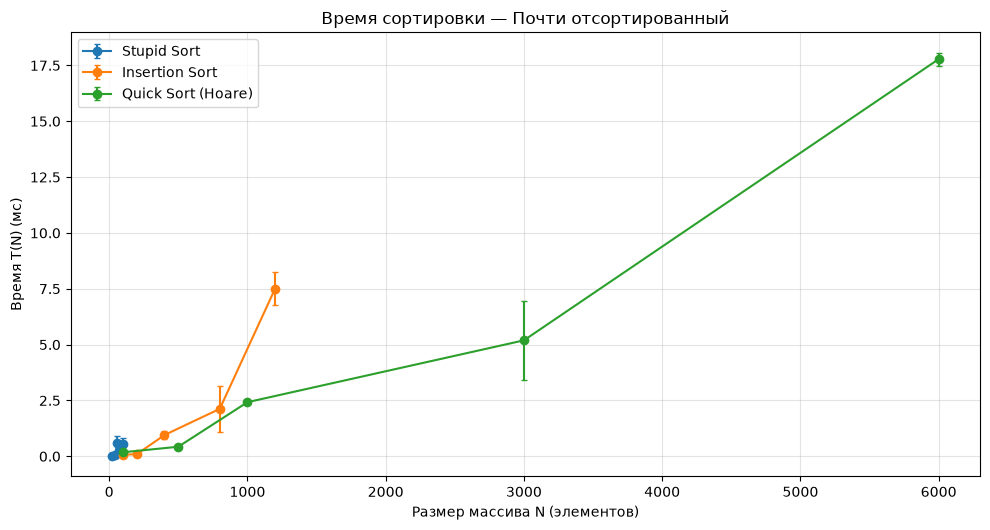

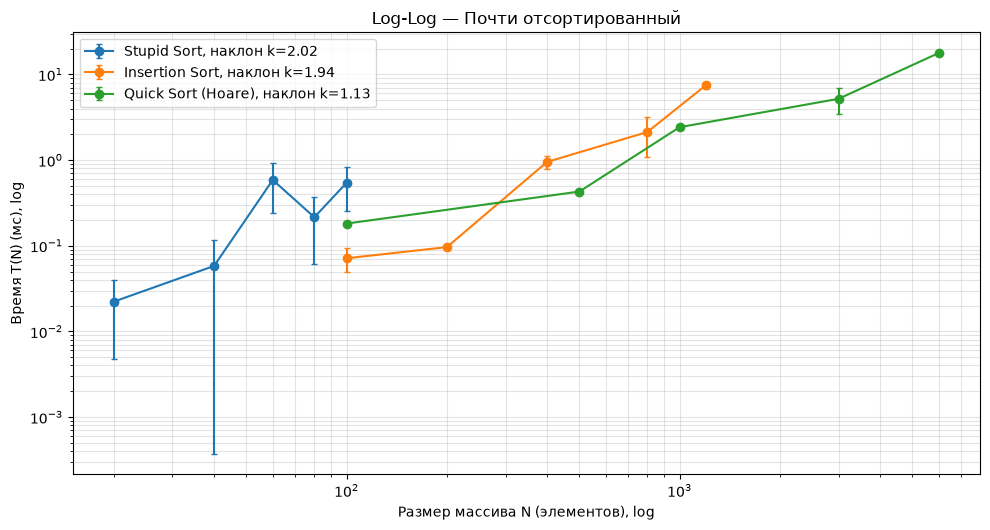

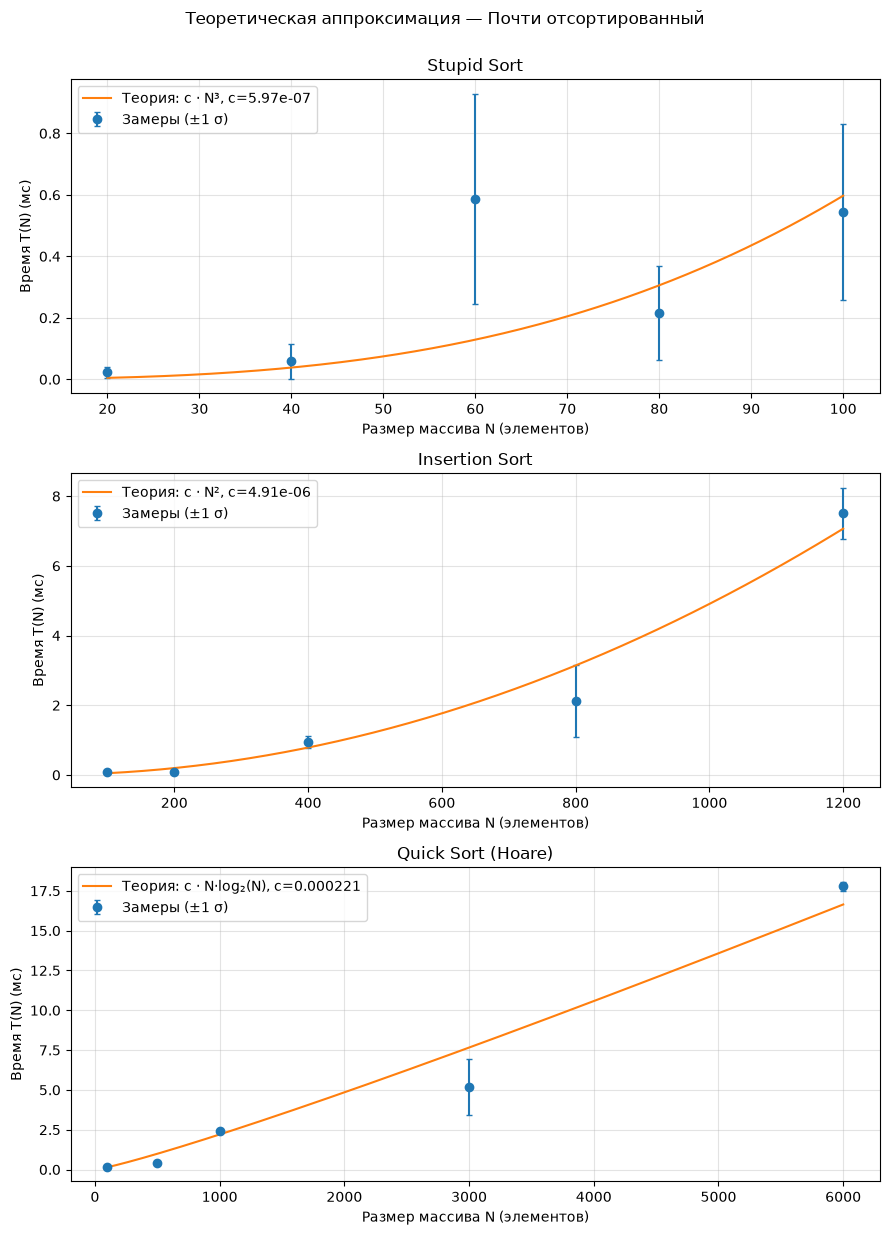

Оценки наклона: {'Stupid Sort': 2.02, 'Insertion Sort': 1.936, 'Quick Sort (Hoare)': 1.132}

 МНОГО ПОВТОРЕНИЙ


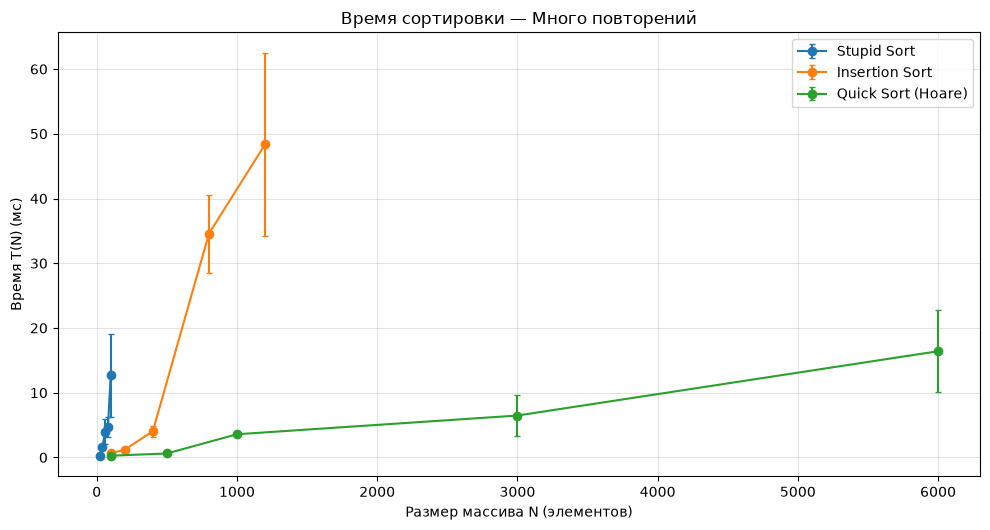

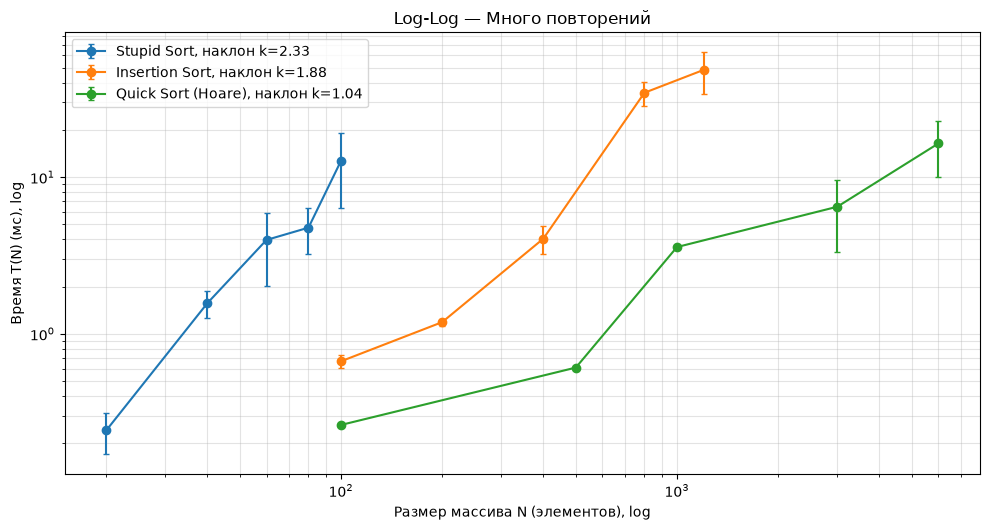

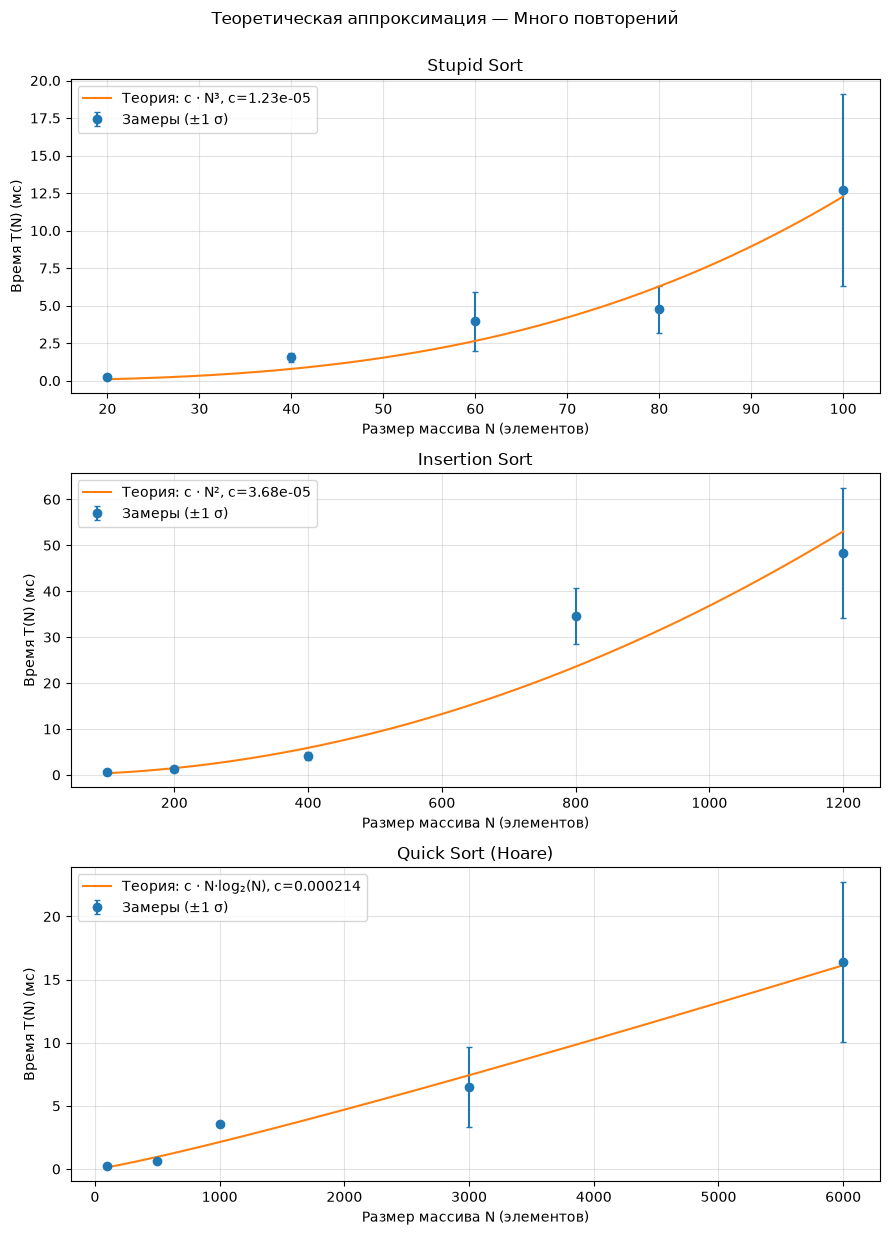

Оценки наклона: {'Stupid Sort': 2.33, 'Insertion Sort': 1.879, 'Quick Sort (Hoare)': 1.038}


In [22]:
for kind in DISTRIBUTIONS:
    print("\n", DISTRIBUTIONS[kind].upper())
    fig = plot_time(summary_rows, kind)
    plt.show()
    fig, current_slopes = plot_loglog(summary_rows, kind)
    plt.show()
    fig, _ = plot_fitting(summary_rows, kind)
    plt.show()
    print("Оценки наклона:", {name: round(k, 3) if k is not None else None
                                for name, k in current_slopes.items()})

## 12. Какой алгоритм использовал меньше сравнений?

Сравнивать нужно **на одинаковом размере и типе входного массива**. Сетки из ТЗ различаются, поэтому на финальном большом графике не всегда есть общие размеры. Ниже для ориентировочного сравнения выведены значения на пересекающихся N; общая сетка N≤500 есть отдельно в Streamlit. Не следует путать число сравнений с длительностью работы.

In [23]:
comparison_table = summary_df[["algorithm", "distribution", "n", "mean_comparisons"]].copy()
display(comparison_table.head(25))

,algorithm,distribution,n,mean_comparisons
0,Stupid Sort,random,20,885.6
1,Stupid Sort,sorted,20,19.0
2,Stupid Sort,reversed,20,1349.0
3,Stupid Sort,nearly_sorted,20,73.8
4,Stupid Sort,duplicates,20,763.0
5,Stupid Sort,random,40,6835.8
6,Stupid Sort,sorted,40,39.0
7,Stupid Sort,reversed,40,10699.0
8,Stupid Sort,nearly_sorted,40,208.8
9,Stupid Sort,duplicates,40,5776.0


## 13. Опциональный бонус: дополнительная память

`tracemalloc` запускается **после создания входного списка**, поэтому здесь измеряется пик дополнительных Python-выделений, а не полная память процесса. Для каждой сортировки показана своя сетка. У Stupid и Insertion дополнительная алгоритмическая память — $O(1)$, у Quick обычно $O(\log N)$ на стек рекурсии.

,algorithm,distribution,n,peak_kib
0,Stupid Sort,random,20,0.062500
1,Stupid Sort,random,50,0.093750
2,Stupid Sort,random,100,0.745117
3,Stupid Sort,random,200,0.828125
4,Insertion Sort,random,100,0.125000
5,Insertion Sort,random,1000,1.218750
6,Insertion Sort,random,3000,0.187500
7,Insertion Sort,random,5000,1.640625
8,Quick Sort (Hoare),random,1000,1.539062
9,Quick Sort (Hoare),random,3000,1.914062


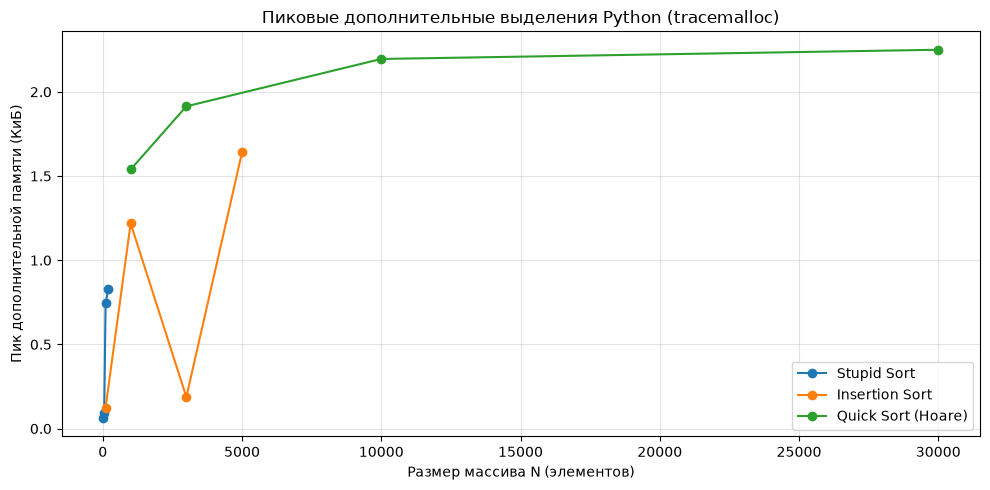

In [24]:
memory_rows = memory_profile()
display(pd.DataFrame(memory_rows))
fig = plot_memory(memory_rows)
plt.show()

## 14. Личный аналитический вывод

пока нету, запуск пробный
## Источники

- Индивидуальное ТЗ кафедры (файл пользователя).
- [Сортировки, материалы курса ФБМФ МФТИ](https://cs.mipt.ru/fbmf/lessons/sem_1/08.sorts.html).
- Python: `time.perf_counter`, `statistics`, `tracemalloc` (стандартная библиотека).
- `matplotlib` / `numpy`: построение графиков и оценка наклона.